# Customer Churn Prediction — Exploratory Data Analysis (EDA)

## Project Overview

This notebook explores the IBM Telco Customer Churn dataset to understand customer behavior, identify data quality issues, and investigate factors associated with customer churn.

**Dataset:** IBM Telco Customer Churn (Kaggle, BlastChar)

**Objective:** Explore customer characteristics and identify potentially useful features for a machine-learning model that predicts whether a customer will churn.

**Key analysis areas:**
- Dataset structure and data quality
- Customer churn distribution
- Contract types, internet services, and payment methods
- Customer tenure and monthly charges
- Insights for model development

In [1]:
import pandas as pd

# Load the raw customer churn dataset
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display dataset dimensions
print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")

Dataset shape: 7043 rows and 21 columns


In [2]:
# Preview the first five customer records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Inspect column data types and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Identify invalid or blank TotalCharges values
invalid_total_charges = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
).isna()

print(f"Invalid or blank TotalCharges values: {invalid_total_charges.sum()}")

# Display affected customers
df.loc[invalid_total_charges, ["customerID", "tenure", "TotalCharges"]]

Invalid or blank TotalCharges values: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


## Data Quality Findings

The dataset contains 7,043 customer records and 21 columns.

**Key findings:**
- All columns initially appear complete according to `df.info()`.
- `TotalCharges` is stored as text instead of a numerical data type.
- There are 11 blank values in `TotalCharges` that Pandas does not initially recognize as missing.
- All 11 affected customers have `tenure = 0`.

**Planned preprocessing:**
- Convert `TotalCharges` to a numerical data type.
- Investigate and handle the 11 blank values. Replacing them with zero is a possible approach because all affected customers have zero tenure.
- Preserve the original raw dataset without modification.

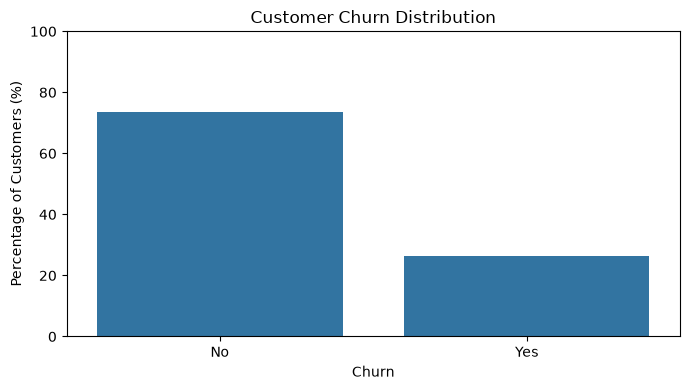

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate customer churn percentages
churn_percentages = df["Churn"].value_counts(normalize=True).mul(100)

# Create the chart
plt.figure(figsize=(7, 4))
sns.barplot(x=churn_percentages.index, y=churn_percentages.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Percentage of Customers (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Customer Churn Distribution

The dataset contains:
- **5,174 customers (73.46%)** who did not churn.
- **1,869 customers (26.54%)** who churned.

### Key Insights

The target variable (`Churn`) is moderately imbalanced, with approximately 73% of customers belonging to the non-churn class.

A model that always predicts "No Churn" would achieve approximately 73.46% accuracy without identifying any customers who actually churn.

Therefore, model evaluation should include:
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

We will also consider stratified train-test splitting to preserve the class distribution.

In [7]:
# Calculate churn percentages for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


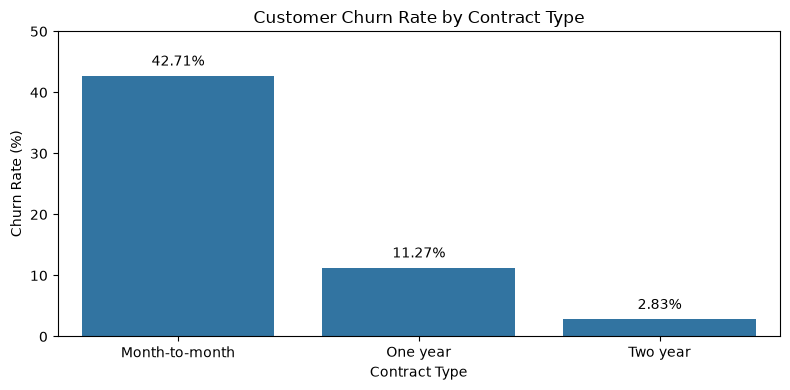

In [8]:
# Visualize customer churn rates by contract type
contract_order = ["Month-to-month", "One year", "Two year"]
churn_rates = contract_churn.loc[contract_order, "Yes"]

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    x=churn_rates.index,
    y=churn_rates.values
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

# Display the percentage above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

## Churn Analysis by Contract Type

Customer churn rates vary substantially across contract types:

- **Month-to-month:** 42.71% churn rate.
- **One-year contract:** 11.27% churn rate.
- **Two-year contract:** 2.83% churn rate.

### Key Insights

Customers with month-to-month contracts have the highest observed churn rate, while customers with two-year contracts have the lowest.

The churn rate for month-to-month customers is approximately 15 times that of customers with two-year contracts.

**Implications for machine learning:**
- `Contract` is a potentially important predictive feature.
- We should include contract type during feature engineering and model training.
- This is an observed association, not proof that changing contract duration would cause churn to decrease.

In [9]:
# Calculate churn percentages by internet service type
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


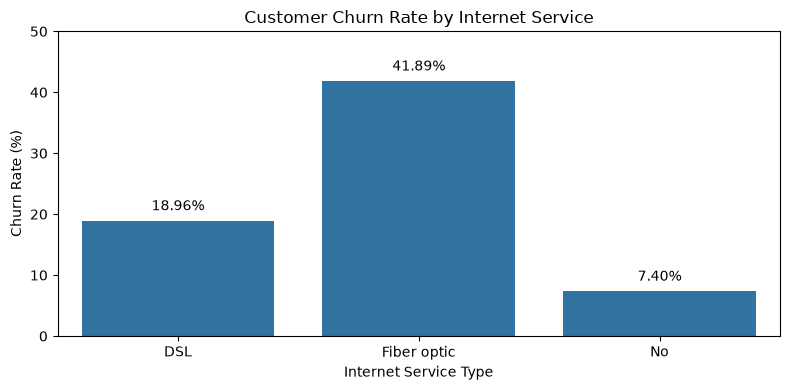

In [10]:
# Visualize churn rates by internet service type
internet_order = ["DSL", "Fiber optic", "No"]
internet_churn_rates = internet_churn.loc[internet_order, "Yes"]

plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=internet_churn_rates.index,
    y=internet_churn_rates.values
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

# Add percentage labels above the bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

## Churn Analysis by Internet Service

Customer churn rates differ across internet service types:

- **DSL:** 18.96% churn rate.
- **Fiber optic:** 41.89% churn rate.
- **No internet service:** 7.40% churn rate.

### Key Insights

Customers using fiber-optic internet have the highest observed churn rate, approximately 2.2 times the rate of DSL customers.

Customers without internet service have the lowest observed churn rate.

**Implications for machine learning:**
- `InternetService` is a potentially useful predictive feature.
- We should include this categorical variable during preprocessing and model training.
- These differences represent associations, not proof that internet service type causes churn.
- Other factors, such as contract type, customer tenure, and monthly charges, may help explain these differences.

In [11]:
# Calculate churn percentages for each payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


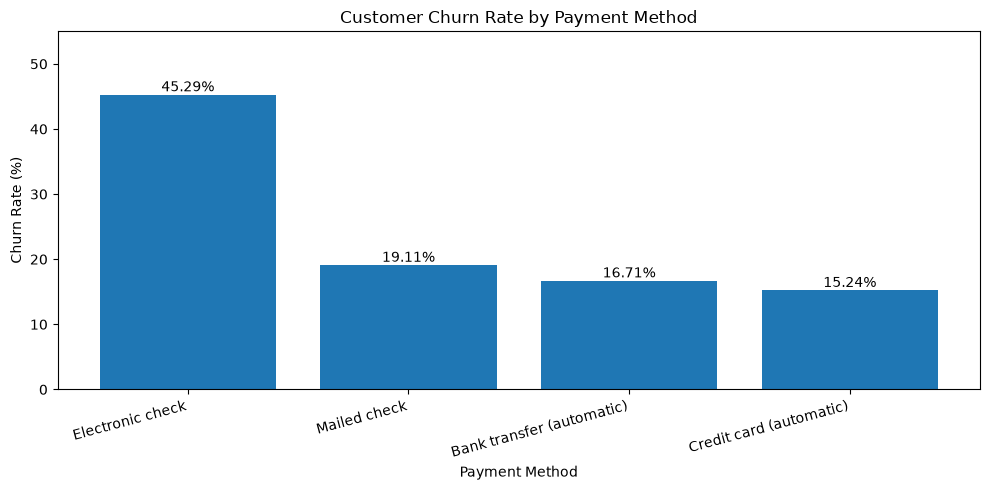

In [12]:
import matplotlib.pyplot as plt

# Extract churn percentages
payment_churn_rates = payment_churn["Yes"].sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(10, 5))

bars = plt.bar(
    payment_churn_rates.index,
    payment_churn_rates.values
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center"
    )

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Churn Analysis by Payment Method

Customer churn rates vary considerably across payment methods:

- **Electronic check:** 45.29% churn rate.
- **Mailed check:** 19.11% churn rate.
- **Bank transfer (automatic):** 16.71% churn rate.
- **Credit card (automatic):** 15.24% churn rate.

### Key Insights

Customers using electronic checks have the highest observed churn rate, approximately three times the rate of customers using automatic credit-card payments.

Customers using automatic payment methods generally have lower observed churn rates than customers using checks.

**Implications for machine learning:**

- `PaymentMethod` is a potentially important predictive feature.
- We should include payment method as a categorical variable during preprocessing and model training.
- These differences show an association, not evidence that changing payment methods would directly reduce churn.
- Other factors, such as contract type, customer tenure, and monthly charges, may help explain these differences.

In [13]:
# Compare customer tenure between churned and retained customers
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

tenure_summary

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


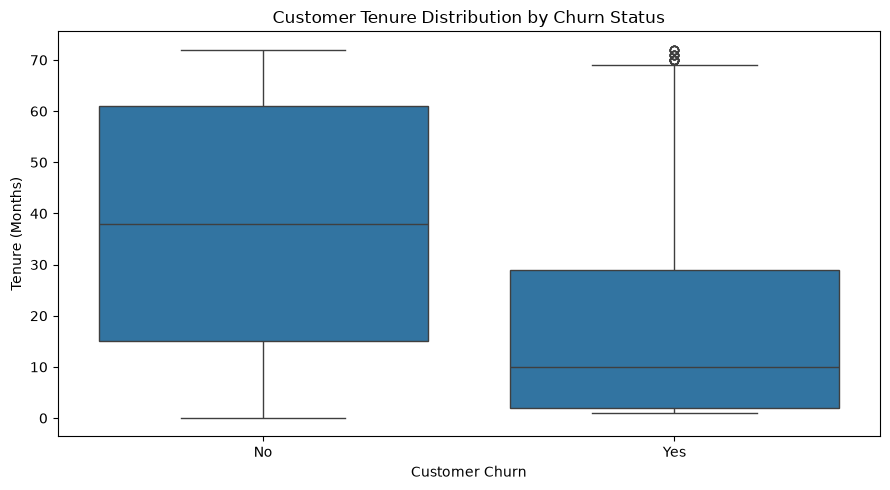

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare tenure distributions by churn status
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    order=["No", "Yes"]
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

## Churn Analysis by Customer Tenure

Customer tenure differs substantially between retained and churned customers.

**Retained customers (No Churn):**
- Average tenure: 37.57 months.
- Median tenure: 38 months.

**Churned customers (Yes Churn):**
- Average tenure: 17.98 months.
- Median tenure: 10 months.

### Key Insights

Customers who churned generally had shorter tenures than customers who remained with the company.

The median tenure of churned customers was 10 months, compared with 38 months for retained customers.

The box plot also shows that churned customers tend to be concentrated at shorter tenures, although some long-tenure customers also churn.

**Implications for machine learning:**

- `tenure` is a potentially important numerical predictive feature.
- We should include tenure during model training.
- We may investigate whether churn risk varies across different tenure ranges.
- These findings represent associations and do not prove that longer tenure directly prevents churn.

In [15]:
# Compare monthly charges between churned and retained customers
monthly_charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

monthly_charges_summary

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


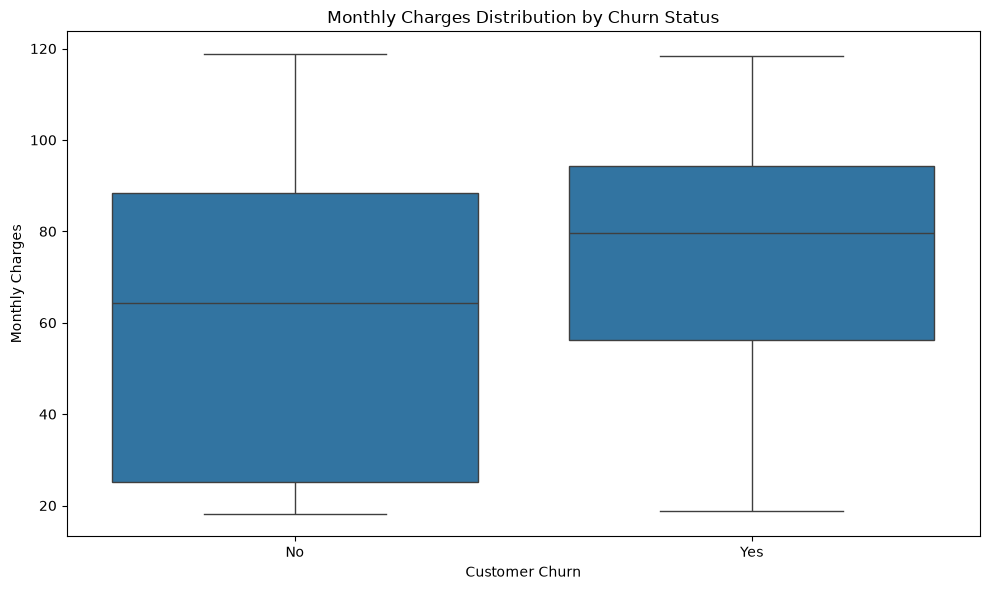

In [16]:
# Visualize monthly charges by churn status
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

### Monthly Charges Analysis — Key Insights

Monthly charges differ between retained and churned customers.

**Retained customers (No Churn):**
- Average monthly charge: 61.27.
- Median monthly charge: 64.43.

**Churned customers (Yes Churn):**
- Average monthly charge: 74.44.
- Median monthly charge: 79.65.

### Key Insights

Customers who churned paid approximately 13.17 more per month on average than retained customers.

The box plot shows that churned customers generally have higher monthly charges, although the distributions overlap considerably.

**Implications for machine learning:**
- `MonthlyCharges` is a potentially useful numerical predictive feature.
- We should include monthly charges during model training.
- Monthly charges should be evaluated alongside other features, such as `Contract`, `tenure`, and `InternetService`.
- These findings show an association, not proof that higher monthly charges directly cause churn.

In [17]:
# Check for duplicate customer IDs
duplicate_ids = df["customerID"].duplicated().sum()

# Check for completely duplicated rows
duplicate_rows = df.duplicated().sum()

print(f"Duplicate customer IDs: {duplicate_ids}")
print(f"Duplicate rows: {duplicate_rows}")

Duplicate customer IDs: 0
Duplicate rows: 0


### Duplicate Records — Data Quality Check

We checked the dataset for duplicate customer IDs and completely duplicated rows.

**Results:**
- Duplicate customer IDs: 0.
- Completely duplicated rows: 0.

**Key findings:**

All 7,043 customer records have unique customer IDs, and no completely duplicated rows were detected.

**Implications for preprocessing:**
- No duplicate records need to be removed.
- `customerID` should be excluded from model training because it is an identifier rather than a meaningful predictive feature.
- The original raw dataset will remain unchanged.

## Final Exploratory Data Analysis Summary

### Dataset Overview

- Total customer records: 7,043.
- Total columns: 21.
- Overall customer churn rate: 26.54%.
- Duplicate customer IDs: 0.
- Completely duplicated rows: 0.
- Data quality issue: 11 blank values in `TotalCharges`, all associated with customers whose `tenure` is 0.

### Main Findings

1. **Contract type:** Month-to-month customers have the highest observed churn rate (42.71%), compared with one-year (11.27%) and two-year contracts (2.83%).
2. **Internet service:** Fiber-optic customers have the highest observed churn rate (41.89%), followed by DSL (18.96%) and customers without internet service (7.40%).
3. **Payment method:** Electronic-check customers have the highest observed churn rate (45.29%).
4. **Customer tenure:** Churned customers have a median tenure of 10 months, compared with 38 months for retained customers.
5. **Monthly charges:** Churned customers pay 74.44 per month on average, compared with 61.27 for retained customers.

### Implications for Model Development

- Exclude `customerID` from predictive features.
- Convert `TotalCharges` to a numeric type and handle its 11 blank values.
- Encode categorical variables such as `Contract`, `InternetService`, and `PaymentMethod`.
- Include numerical features such as `tenure`, `MonthlyCharges`, and `TotalCharges`.
- Use a stratified train-test split to preserve the churn distribution.
- Evaluate models using precision, recall, F1-score, ROC-AUC, and a confusion matrix rather than accuracy alone.
- Avoid data leakage by fitting preprocessing transformations only on training data.

### Conclusion

The exploratory analysis identified several customer characteristics associated with churn. These findings will guide preprocessing, feature selection, and model evaluation during the next development phase.

The observed relationships are associations and should not be interpreted as evidence of causation.